# TripoSR: Images → 3D models → Colored point clouds (8,192 points)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Md-Mosabbir/localpoint3d/blob/main/notebooks/triposr.ipynb)

This notebook runs [TripoSR](https://github.com/VAST-AI-Research/TripoSR) (single image → 3D mesh) on a batch of your images, then turns every 3D model into a **colored point cloud with exactly 8,192 points**.

**What you get**

1. Upload a batch of images (or point the notebook to a Drive folder).
2. Every image → a colored 3D model, saved as `.ply` only.
3. Every 3D model → a colored 8,192-point cloud (`.ply` with RGB, plus an optional `(8192, 6)` `.npy` = x y z r g b).
4. Everything is saved to your Google Drive (no ZIP downloads).

**Before you start:** `Runtime → Change runtime type → T4 GPU`, then run the cells from top to bottom.

**Good to know**

- TripoSR sees only one view, so the back of the object is a *guess*. The shape and colors are estimates, not a scan.
- Colors come from TripoSR's per-vertex color prediction. The point cloud takes its colors from the 3D model's surface, so the point colors match the 3D model.
- The 3D model has an arbitrary scale. Set `NORMALIZE_POINTCLOUD = True` in the settings if you want the clouds centered and scaled to a unit sphere.
- Points are sampled uniformly over the mesh surface (area-weighted), with colors interpolated across each triangle.

## 1. Install and load TripoSR

> If Colab asks you to **restart the session** after the install cell, do it, then continue from the next cell (you do not need to run the install cell again).

To make the install fast and reliable, this notebook does **not** compile `torchmcubes` (the slow, often-failing part of TripoSR's install). It plugs in scikit-image's marching cubes instead. Same result, runs on CPU in about a second per model.

In [1]:
%pip install "transformers>=4.38,<5" omegaconf einops trimesh "rembg[cpu]" scikit-image imageio pillow-heif plotly pandas tqdm

In [2]:
import sys, types, subprocess
from pathlib import Path

import numpy as np
import torch
from skimage import measure

REPO_DIR = Path("/content/TripoSR")
if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/VAST-AI-Research/TripoSR.git", str(REPO_DIR)], check=True)


# --- Drop-in replacement for torchmcubes.marching_cubes (uses scikit-image) ---
# torchmcubes returns vertex coordinates in reversed axis order (TripoSR flips them back with [2, 1, 0]),
# so we reverse the columns here to match.
def marching_cubes(vol, thresh):
    volume = vol.detach().float().cpu().numpy()
    if not (float(volume.min()) < thresh < float(volume.max())):
        raise ValueError("TripoSR found no surface in this image. Try another image, or switch REMOVE_BACKGROUND.")
    verts, faces, _, _ = measure.marching_cubes(volume, level=float(thresh))
    verts = np.ascontiguousarray(verts[:, ::-1])
    return torch.from_numpy(verts).float(), torch.from_numpy(faces.astype(np.int64))


_shim = types.ModuleType("torchmcubes")
_shim.marching_cubes = marching_cubes
sys.modules["torchmcubes"] = _shim
sys.path.insert(0, str(REPO_DIR))
print("TripoSR cloned to", REPO_DIR)

TripoSR cloned to /content/TripoSR


In [3]:
import rembg
from PIL import Image, ImageOps
from tsr.system import TSR
from tsr.utils import remove_background, resize_foreground
import tsr.models.isosurface as _iso

if getattr(_iso, "marching_cubes", None) is not marching_cubes:
    print("WARNING: TripoSR is not using the scikit-image marching cubes. Restart the session and run the cells again from the top.")

DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.startswith("cuda") else "no GPU found")
if DEVICE == "cpu":
    print("WARNING: no GPU. It will work but be slow. Use Runtime > Change runtime type > T4 GPU.")

model = TSR.from_pretrained(
    "stabilityai/TripoSR",
    config_name="config.yaml",
    weight_name="model.ckpt",
)
model.renderer.set_chunk_size(8192)
model.to(DEVICE)
rembg_session = rembg.new_session()
print("TripoSR loaded.")

Device: cuda:0 | Tesla T4


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


TripoSR loaded.


## 2. Settings

Change anything here, then run the cell.

In [ ]:
# ---------------- Settings ----------------
MC_RESOLUTION        = 192     # 3D model detail (marching-cubes grid). 256 is TripoSR's default; 320 = finer but slower.
REMOVE_BACKGROUND    = False    # True for normal photos. Set False if your images already have a clean/transparent background.
FOREGROUND_RATIO     = 0.85    # how much of the frame the object fills after background removal

NUM_POINTS           = 8192    # points per point cloud
NORMALIZE_POINTCLOUD = False   # True = center the cloud and scale it into a unit sphere
SAVE_NPY             = True    # also save an (NUM_POINTS, 6) float32 .npy: x y z r g b (colors 0-1)
ORIENT_UPRIGHT       = True    # rotate the 3D model the way TripoSR's own demo does (upright in most viewers)
RANDOM_SEED          = 0

# Input: False = upload from your computer, True = read images from a Google Drive folder
USE_DRIVE_INPUT      = False
DRIVE_INPUT_DIR      = "/content/drive/MyDrive/my_images"   # only used if USE_DRIVE_INPUT = True

DRIVE_OUTPUT_FOLDER  = "TripoSR_Batches"                    # created inside My Drive
# ------------------------------------------

import re, gc, shutil, zipfile, time
from datetime import datetime

WORK        = Path("/content/triposr_work")
INPUT_DIR   = WORK / "input_images"
OUT         = WORK / "output"
MESH_DIR    = OUT / "3d_models"
PREVIEW_DIR = OUT / "previews"
PLY_DIR     = OUT / f"point_clouds_{NUM_POINTS}_ply"
NPY_DIR     = OUT / f"point_clouds_{NUM_POINTS}_npy"
for d in (INPUT_DIR, MESH_DIR, PREVIEW_DIR, PLY_DIR):
    d.mkdir(parents=True, exist_ok=True)
if SAVE_NPY:
    NPY_DIR.mkdir(parents=True, exist_ok=True)

try:                                   # lets Pillow open iPhone .heic photos
    from pillow_heif import register_heif_opener
    register_heif_opener()
except Exception:
    pass

IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".heic", ".heif"}
print("Settings saved. Output folder:", OUT)

## 3. Load your batch of images

- **Upload mode:** a file picker opens. Select many images at once. You can also upload a single `.zip` of images.
- **Drive mode:** set `USE_DRIVE_INPUT = True` and `DRIVE_INPUT_DIR` in the settings.

In [ ]:
from google.colab import files, drive

if USE_DRIVE_INPUT:
    drive.mount("/content/drive")
    src = Path(DRIVE_INPUT_DIR)
    if not src.is_dir():
        raise FileNotFoundError(f"Folder not found: {src}")
    for p in src.rglob("*"):
        if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES:
            shutil.copy(p, INPUT_DIR / p.name)
else:
    uploaded = files.upload()
    for name in uploaded:
        p = Path(name)
        if p.suffix.lower() == ".zip":
            with zipfile.ZipFile(p) as z:
                z.extractall(INPUT_DIR / p.stem)
            p.unlink()
        else:
            shutil.move(str(p), str(INPUT_DIR / p.name))

image_paths = sorted(p for p in INPUT_DIR.rglob("*")
                     if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES
                     and not p.name.startswith("._") and "__MACOSX" not in p.parts)

# Give every image a unique, filesystem-safe name (used for all its output files)
image_jobs, used = [], {}
for p in image_paths:
    base = re.sub(r"[^\w\-]+", "_", p.stem).strip("_") or "image"
    used[base] = used.get(base, 0) + 1
    image_jobs.append((p, base if used[base] == 1 else f"{base}_{used[base]}"))

print(f"{len(image_jobs)} images ready:")
for p, n in image_jobs[:15]:
    print("  ", p.name, "->", n)
if len(image_jobs) > 15:
    print(f"   ... and {len(image_jobs) - 15} more")


if not USE_DRIVE_INPUT:
    del uploaded      # free the uploaded file bytes from RAM
gc.collect()

## 4. Images → 3D models

Each image is cleaned (background removed), reconstructed by TripoSR, and saved as a colored `.ply` (vertex colors). If Colab disconnects, run this cell again: finished images are skipped.

In [ ]:
import trimesh
import pandas as pd
from tqdm.auto import tqdm


def preprocess(path):
    img = ImageOps.exif_transpose(Image.open(path))
    if img.mode not in ("RGB", "RGBA"):
        img = img.convert("RGB")
    if REMOVE_BACKGROUND:
        img = remove_background(img, rembg_session)
        img = resize_foreground(img, FOREGROUND_RATIO)
        arr = np.array(img).astype(np.float32) / 255.0
        arr = arr[:, :, :3] * arr[:, :, 3:4] + (1 - arr[:, :, 3:4]) * 0.5     # gray background, as in TripoSR's run.py
        img = Image.fromarray((arr * 255.0).astype(np.uint8))
    else:
        img = img.convert("RGB")
    return img


def image_to_mesh(img):
    with torch.no_grad():
        scene_codes = model(img, device=DEVICE)
        mesh = model.extract_mesh(scene_codes, True, resolution=MC_RESOLUTION)[0]
    del scene_codes
    if ORIENT_UPRIGHT:                                                        # same orientation fix as TripoSR's gradio_app.py
        mesh.apply_transform(trimesh.transformations.rotation_matrix(-np.pi / 2, [1, 0, 0]))
        mesh.apply_scale([1, 1, -1])
        mesh.apply_transform(trimesh.transformations.rotation_matrix(np.pi / 2, [0, 1, 0]))
    try:                                                                      # keep the faces pointing outwards
        if mesh.volume < 0:
            mesh.invert()
    except Exception:
        pass
    return mesh


mesh_rows = []
for path, name in tqdm(image_jobs, desc="Images → 3D"):
    t0 = time.time()
    outs = [MESH_DIR / f"{name}.ply"]
    try:
        if all(o.exists() for o in outs):
            status = "already done"
        else:
            img = preprocess(path)
            img.save(PREVIEW_DIR / f"{name}_input.png")
            mesh = image_to_mesh(img)
            for o in outs:
                mesh.export(o)
            status = "success"
    except Exception as exc:                  # one bad image must not stop the batch
        status = f"failed: {exc!r}"
    finally:
        img = mesh = None
        gc.collect()
        if DEVICE.startswith("cuda"):
            torch.cuda.empty_cache()
    mesh_rows.append({"name": name, "image": path.name, "status": status, "seconds": round(time.time() - t0, 1)})

mesh_table = pd.DataFrame(mesh_rows)
mesh_table.to_csv(OUT / "mesh_manifest.csv", index=False)
print(mesh_table.status.value_counts().to_string())
display(mesh_table[~mesh_table.status.isin(["success", "already done"])])

## 5. 3D models → colored point clouds (8,192 points)

Reads each saved 3D model, samples `NUM_POINTS` points evenly over its surface, and gives each point the color of the surface under it (interpolated from the model's vertex colors).

Outputs per model: `point_clouds_8192_ply/<name>.ply` (x y z + red green blue) and, if `SAVE_NPY`, `point_clouds_8192_npy/<name>.npy` with shape `(8192, 6)`.

In [8]:
def save_colored_ply(path, xyz, rgb):
    header = ("ply\nformat ascii 1.0\n"
              f"element vertex {len(xyz)}\n"
              "property float x\nproperty float y\nproperty float z\n"
              "property uchar red\nproperty uchar green\nproperty uchar blue\n"
              "end_header\n")                      # exactly 10 header lines
    with open(path, "w") as f:
        f.write(header)
        for p, c in zip(xyz, rgb):
            f.write(f"{p[0]:.6f} {p[1]:.6f} {p[2]:.6f} {int(c[0])} {int(c[1])} {int(c[2])}\n")


def load_colored_ply(path):
    data = np.loadtxt(path, skiprows=10, dtype=np.float32)
    return data[:, :3], data[:, 3:6].astype(np.uint8)


def mesh_to_colored_points(mesh, n, seed=0):
    if mesh.visual.kind != "vertex":
        raise ValueError("The 3D model has no vertex colors.")
    np.random.seed(seed)
    try:
        points, face_idx = trimesh.sample.sample_surface(mesh, n, seed=seed)
    except TypeError:                               # older trimesh without the seed argument
        points, face_idx = trimesh.sample.sample_surface(mesh, n)
    bary = trimesh.triangles.points_to_barycentric(mesh.triangles[face_idx], points)
    bary = np.nan_to_num(bary, nan=1 / 3)
    vertex_rgb = np.asarray(mesh.visual.vertex_colors)[:, :3].astype(np.float32)
    corner_rgb = vertex_rgb[mesh.faces[face_idx]]                         # (n, 3 corners, 3 channels)
    rgb = np.clip((bary[:, :, None] * corner_rgb).sum(axis=1), 0, 255).astype(np.uint8)
    points = np.asarray(points, dtype=np.float32)
    if NORMALIZE_POINTCLOUD:
        points = points - points.mean(axis=0)
        points = points / np.linalg.norm(points, axis=1).max()
    return points, rgb


pc_rows = []
mesh_files = sorted(MESH_DIR.glob("*.ply"))
for mesh_path in tqdm(mesh_files, desc="3D → point cloud"):
    name = mesh_path.stem
    try:
        mesh = trimesh.load(mesh_path, process=False, force="mesh")
        xyz, rgb = mesh_to_colored_points(mesh, NUM_POINTS, RANDOM_SEED)
        assert len(xyz) == NUM_POINTS
        save_colored_ply(PLY_DIR / f"{name}.ply", xyz, rgb)
        if SAVE_NPY:
            np.save(NPY_DIR / f"{name}.npy", np.hstack([xyz, rgb / 255.0]).astype(np.float32))
        status = "success"
    except Exception as exc:
        status = f"failed: {exc!r}"
    pc_rows.append({"name": name, "points": NUM_POINTS, "status": status})

pc_table = pd.DataFrame(pc_rows)
pc_table.to_csv(OUT / "pointcloud_manifest.csv", index=False)
print(pc_table.status.value_counts().to_string())
display(pc_table[pc_table.status != "success"])

3D → point cloud:   0%|          | 0/89 [00:00<?, ?it/s]

status
success    89


,name,points,status


## 6. Check the results

Input image (top) and its colored point cloud (bottom). Always look at these before trusting the clouds.

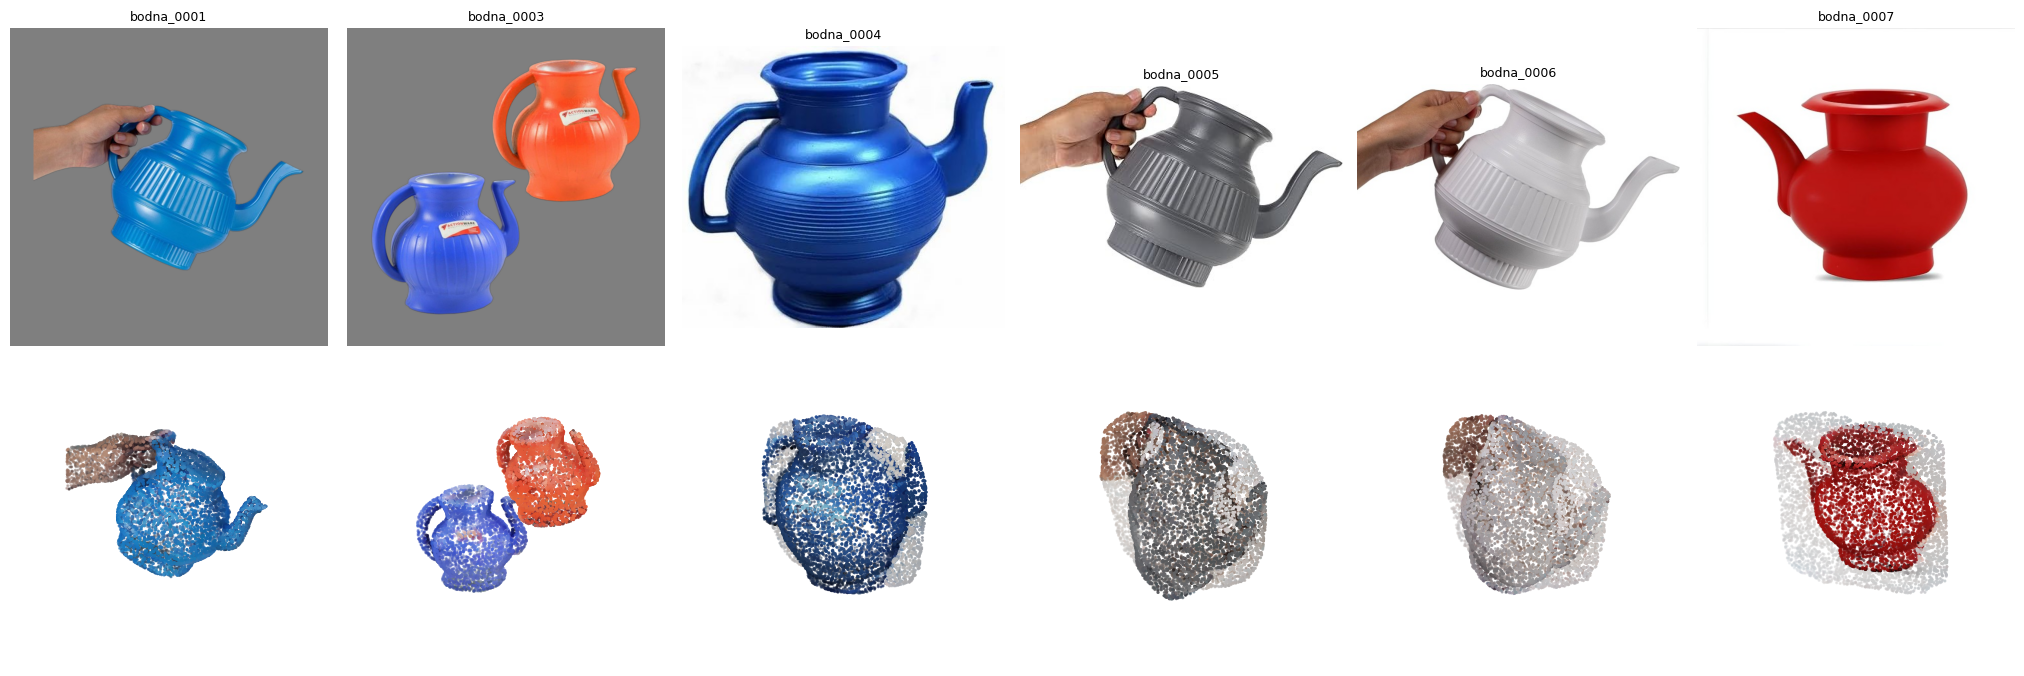

In [9]:
import matplotlib.pyplot as plt

PREVIEW_COUNT = 6
names = [r["name"] for r in pc_rows if r["status"] == "success"][:PREVIEW_COUNT]

if names:
    fig = plt.figure(figsize=(3.4 * len(names), 6.8))
    for i, name in enumerate(names):
        ax = fig.add_subplot(2, len(names), i + 1)
        img_path = PREVIEW_DIR / f"{name}_input.png"
        if img_path.exists():
            ax.imshow(Image.open(img_path))
        ax.set_title(name, fontsize=9)
        ax.axis("off")

        xyz, rgb = load_colored_ply(PLY_DIR / f"{name}.ply")
        ax = fig.add_subplot(2, len(names), len(names) + i + 1, projection="3d")
        ax.scatter(xyz[:, 0], xyz[:, 2], xyz[:, 1], c=rgb / 255.0, s=1.5)       # y is "up"
        ax.set_box_aspect(np.ptp(xyz[:, [0, 2, 1]], axis=0) + 1e-6)
        ax.view_init(elev=15, azim=-60)
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()
else:
    print("No point clouds to show.")

**Interactive viewer:** set `NAME` to one of the names above and run the cell to rotate and zoom the colored cloud.

In [10]:
import plotly.graph_objects as go

NAME = names[0] if names else ""        # e.g. NAME = "my_chair"

if NAME:
    xyz, rgb = load_colored_ply(PLY_DIR / f"{NAME}.ply")
    fig = go.Figure(go.Scatter3d(
        x=xyz[:, 0], y=xyz[:, 2], z=xyz[:, 1], mode="markers",
        marker=dict(size=2, color=[f"rgb({r},{g},{b})" for r, g, b in rgb]),
    ))
    fig.update_layout(title=f"{NAME}: {len(xyz)} points", scene=dict(aspectmode="data"), height=600)
    fig.show()

## 7. Save everything to Google Drive

Copies the full output (`.ply` 3D models, point clouds, previews, manifests) to  
`My Drive / TripoSR_Batches / batch_<date>_<time>/`. Nothing is zipped or downloaded: open the folder in Google Drive.

In [ ]:
drive.mount("/content/drive")                      # running this twice is fine

run_name = datetime.now().strftime("batch_%Y%m%d_%H%M%S")
drive_dir = Path("/content/drive/MyDrive") / DRIVE_OUTPUT_FOLDER / run_name
drive_dir.parent.mkdir(parents=True, exist_ok=True)

# .glb / .obj are never copied, even if an older run left them in the session
shutil.copytree(OUT, drive_dir, ignore=shutil.ignore_patterns("*.glb", "*.obj"))

n_mesh = len(list((drive_dir / "3d_models").glob("*.ply")))
n_pc = len(list((drive_dir / f"point_clouds_{NUM_POINTS}_ply").glob("*.ply")))
print("Saved to Google Drive:", drive_dir)
print(f"  {n_mesh} 3D models (.ply) and {n_pc} point clouds ({NUM_POINTS} points, .ply)")

## Troubleshooting

- **Out of GPU memory:** lower `MC_RESOLUTION` (e.g. 192) or restart the runtime and run again.
- **Background removal cuts off part of the object:** set `REMOVE_BACKGROUND = False` for that batch (works best when the object already sits on a plain background).
- **"found no surface" for an image:** the object was not recognized. Try a clearer, centered photo of a single object.
- **Install problems after `%pip install`:** `Runtime → Restart session`, then run from the "Install and load" cells onward.